<a href="https://colab.research.google.com/github/vedadm17/Credit-Risk-Prediction/blob/main/Machine_Learning_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Import Necessary Libraries

In [1]:
# Import necessary libraries
import matplotlib.pyplot as plt  # Import matplotlib for visualization plotting
import numpy as np  # Import numpy for array manipulation and numerical operations
import pandas as pd  # Import pandas for data manipulation and analysis
import seaborn as sns  # Import seaborn for statistical data visualization
from imblearn.over_sampling import (
    SMOTE,  # Import SMOTE for handling class imbalance via synthetic oversampling
)
from sklearn.ensemble import (
    AdaBoostClassifier,  # Import AdaBoost classifier
    GradientBoostingClassifier,  # Import Gradient Boosting classifier
    RandomForestClassifier,  # Import Random Forest classifier
)
from sklearn.metrics import (
    accuracy_score,  # Import accuracy metric
    classification_report,  # Import classification report generator
    confusion_matrix,  # Import confusion matrix calculation
    roc_auc_score,  # Import ROC-AUC score evaluation
    roc_curve,  # Import ROC curve plotting function
)
from sklearn.model_selection import (
    train_test_split,  # Import utility to split data into train and test sets
)
from sklearn.preprocessing import (
    StandardScaler,  # Import standard scaler for feature scaling
)

Data Loading and Imputation

In [2]:
# Load the credit risk dataset
df = pd.read_csv("credit_risk_dataset.csv")  # Read dataset from CSV into a pandas DataFrame

# Data Preprocessing - Handling Missing Values using recommended pandas assignment
df["person_emp_length"] = df["person_emp_length"].fillna(
    df["person_emp_length"].median()
)  # Impute missing employment lengths with median value

df["loan_int_rate"] = df["loan_int_rate"].fillna(
    df["loan_int_rate"].median()
)  # Impute missing interest rates with median value

# Quick preview of the preprocessed dataset
display(df.head())

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


Encoding Features and Train-Test Split




In [3]:
# Encoding Categorical Features using One-Hot Encoding
df_encoded = pd.get_dummies(
    df, drop_first=True
)  # Convert categorical variables into dummy indicators, dropping first level

# Define Feature Matrix (X) and Target Vector (y)
X = df_encoded.drop(
    "loan_status", axis=1
)  # Drop target variable to create feature matrix
y = df_encoded["loan_status"]  # Extract target column (0: non-default, 1: default)

# Train-Test Split with Stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)  # Perform 80-20 stratified train-test split

Feature Scaling and Class Imbalance Oversampling

In [4]:
# Scale numerical features
scaler = StandardScaler()  # Instantiate StandardScaler
X_train_scaled = scaler.fit_transform(
    X_train
)  # Fit scaler on training data and transform it
X_test_scaled = scaler.transform(
    X_test
)  # Transform test data using fitted scaler

# Apply SMOTE to balance the training set
smote = SMOTE(
    random_state=42
)  # Instantiate SMOTE object with fixed random state
X_train_res, y_train_res = smote.fit_resample(
    X_train_scaled, y_train
)  # Resample training features and targets to balance classes

Model Initialization,Training and Evaluation

In [5]:
# Initialize Ensemble Models
rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42
)  # Initialize Random Forest with 100 trees
ada_model = AdaBoostClassifier(
    n_estimators=100, random_state=42
)  # Initialize AdaBoost with 100 estimators
gb_model = GradientBoostingClassifier(
    n_estimators=100, random_state=42
)  # Initialize Gradient Boosting with 100 estimators

# Dictionary to store trained models
models = {"Random Forest": rf_model, "AdaBoost": ada_model, "Gradient Boosting": gb_model}

# Train models and generate predictions
results = {}  # Dictionary to store performance metrics
for name, model in models.items():  # Iterate through each algorithm
    model.fit(X_train_res, y_train_res)  # Fit model on SMOTE-balanced training data
    y_pred = model.predict(X_test_scaled)  # Predict class labels for test set
    y_prob = model.predict_proba(X_test_scaled)[
        :, 1
    ]  # Predict probabilities for positive class (default)

    # Calculate and store performance metrics
    acc = accuracy_score(y_test, y_pred)  # Calculate accuracy score
    auc = roc_auc_score(y_test, y_prob)  # Calculate ROC-AUC score
    results[name] = {
        "Accuracy": acc,
        "ROC-AUC": auc,
        "Report": classification_report(y_test, y_pred),
    }  # Store output in dictionary

    # Print individual model results
    print(f"=== {name} Performance ===")  # Print model header name
    print(f"Accuracy: {acc:.4f}")  # Print accuracy score formatted to 4 decimals
    print(f"ROC-AUC Score: {auc:.4f}")  # Print ROC-AUC score formatted to 4 decimals
    print(classification_report(y_test, y_pred))  # Print detailed classification report
    print("-" * 50)  # Print separator line

=== Random Forest Performance ===
Accuracy: 0.9224
ROC-AUC Score: 0.9299
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      5095
           1       0.89      0.73      0.80      1422

    accuracy                           0.92      6517
   macro avg       0.91      0.85      0.88      6517
weighted avg       0.92      0.92      0.92      6517

--------------------------------------------------
=== AdaBoost Performance ===
Accuracy: 0.8464
ROC-AUC Score: 0.8892
              precision    recall  f1-score   support

           0       0.93      0.87      0.90      5095
           1       0.62      0.77      0.69      1422

    accuracy                           0.85      6517
   macro avg       0.78      0.82      0.79      6517
weighted avg       0.86      0.85      0.85      6517

--------------------------------------------------
=== Gradient Boosting Performance ===
Accuracy: 0.8998
ROC-AUC Score: 0.9200
              precision   

Comparative Model Evaluation

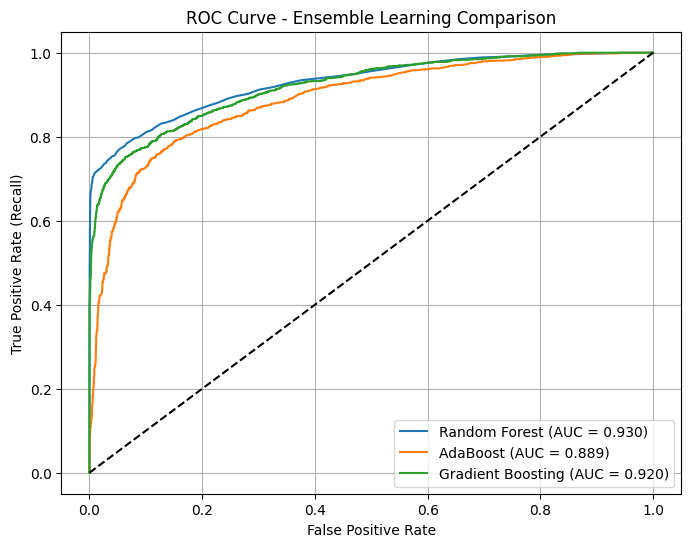

In [6]:
# Plot ROC Curves for comparison
plt.figure(figsize=(8, 6))  # Set plot figure size
for name, model in models.items():  # Loop through models to plot ROC curves
    y_prob = model.predict_proba(X_test_scaled)[
        :, 1
    ]  # Predict probabilities for positive class
    fpr, tpr, _ = roc_curve(
        y_test, y_prob
    )  # Compute false positive rate and true positive rate
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})",  # Plot curve line with label
    )

plt.plot([0, 1], [0, 1], "k--")  # Plot diagonal random baseline line
plt.xlabel("False Positive Rate")  # Set x-axis label
plt.ylabel("True Positive Rate (Recall)")  # Set y-axis label
plt.title("ROC Curve - Ensemble Learning Comparison")  # Set chart title
plt.legend()  # Display chart legend
plt.grid(True)  # Display plot grid lines
plt.show()  # Display plot window

Feature Importance Analysis

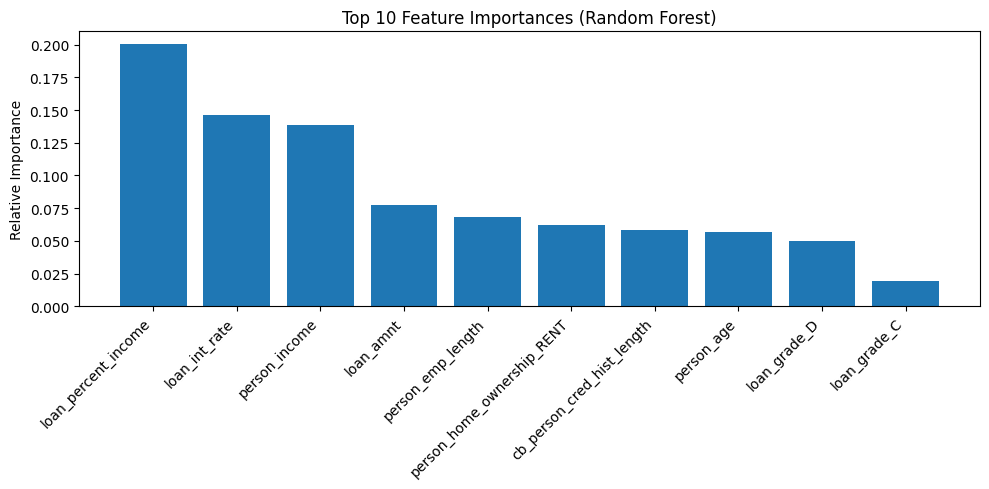

In [7]:
# Plot Feature Importance using Random Forest Model
importances = rf_model.feature_importances_  # Extract feature importance values from Random Forest
indices = np.argsort(importances)[::-1][
    :10
]  # Sort feature importances in descending order (top 10)

plt.figure(figsize=(10, 5))  # Set plot figure size
plt.title("Top 10 Feature Importances (Random Forest)")  # Set title
plt.bar(
    range(10), importances[indices], align="center"
)  # Create bar plot for feature importances
plt.xticks(
    range(10), X.columns[indices], rotation=45, ha="right"
)  # Label x-axis with feature names
plt.ylabel("Relative Importance")  # Set y-axis label
plt.tight_layout()  # Adjust layout to fit labels cleanly
plt.show()  # Display plot window